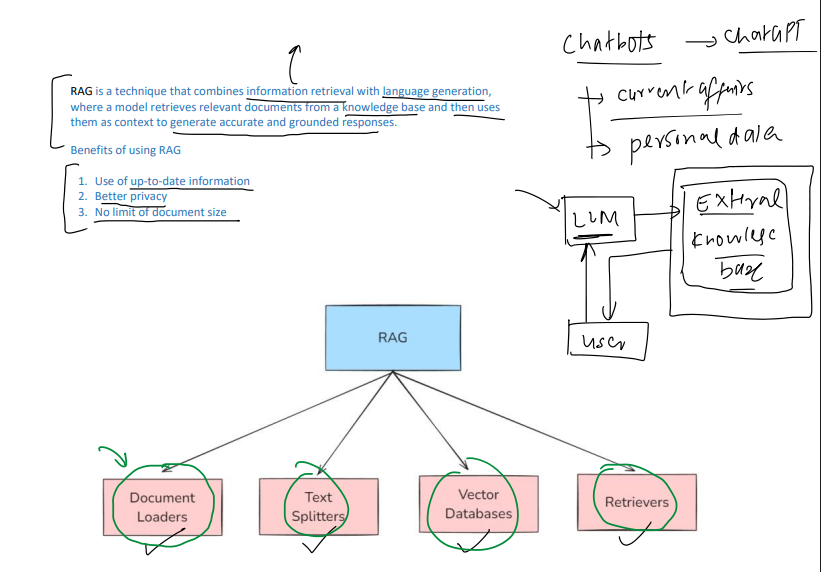
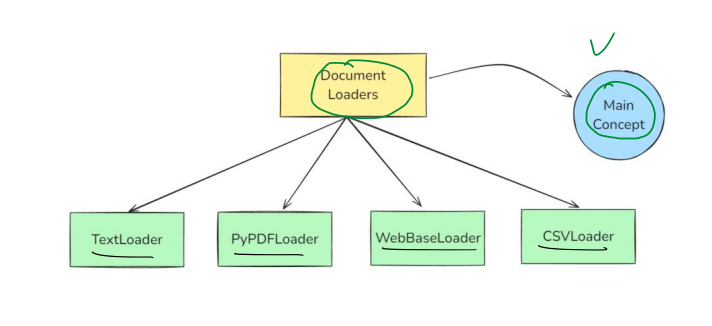
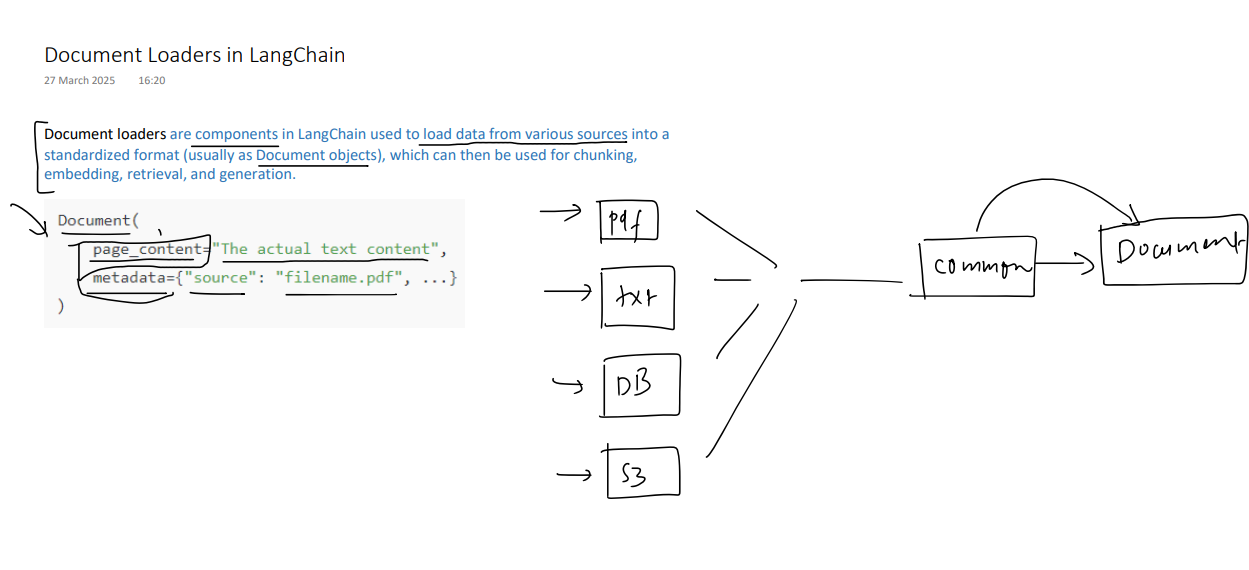

### text loader

###### stores in the form of document of list

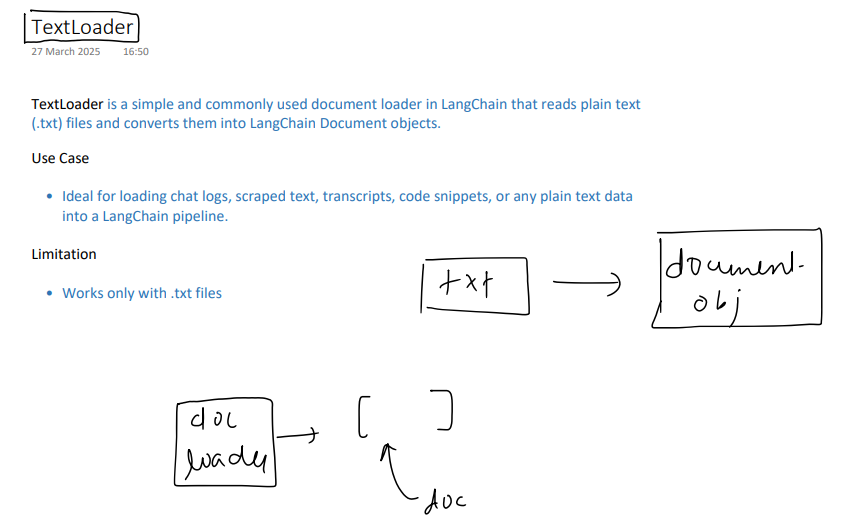

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_groq import ChatGroq
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv

load_dotenv()

model = ChatGroq(model="openai/gpt-oss-120b")

prompt = PromptTemplate(
    template='Write a summary for the following poem - \n {poem}',
    input_variables=['poem']
)

parser = StrOutputParser()

loader = TextLoader('cricket.txt', encoding='utf-8')

docs = loader.load()

print(type(docs))

print(len(docs))

print(docs[0].page_content)

print(docs[0].metadata)

chain = prompt | model | parser

print(chain.invoke({'poem':docs[0].page_content}))


<class 'list'>
1
Beneath the sun or floodlight's gleam,

Cricket lives like a waking dream.

A field of green, a willowed sound,

Where legends rise and tales are found.

From dusty lanes where barefoot boys,

Chase every run with shrieks of joy,

To packed arenas roaring loud,

The game unites a global crowd.

A coin is tossed, the captains stare,

As tension thickens in the air.

Bat or bowl? A choice so bold,

A story new begins, retold.

The openers walk, calm yet brave,

Each stride a wave upon the wave.

They face the ball with narrowed eyes,

As silence grips the watching skies.

The bowler runs, a rhythmic beat,

Like thunder galloping on feet.

A leather flash, a wooden crack—

The ball takes flight, then tumbles back.

A flick through square, a drive through mid,

A lofted shot the fielder missed.

A single, double, sprint for three,

The crowd erupts in ecstasy.

But not for long—the trap is set,

The spinner loops, the pitch is wet.

A sudden turn, the bat’s deceived,

And 

#### PDFLOADER

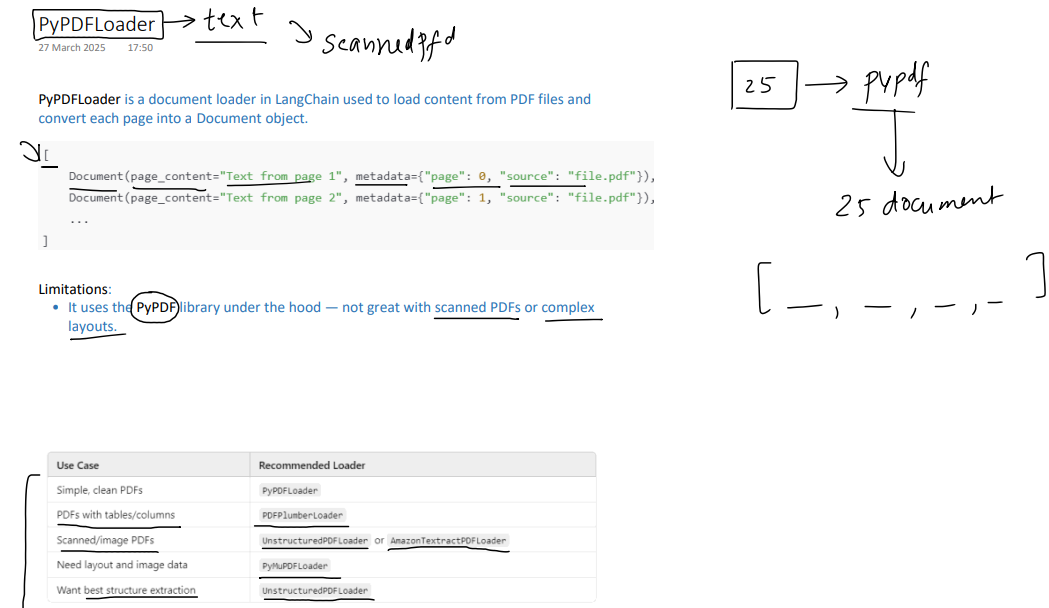

In [2]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader('Proposal.pdf')

docs = loader.load()

print(len(docs))

print(docs[0].page_content)
print(docs[1].metadata)

9
BUSINESS PROPOSAL
“SuryaSheetal” – Solar-Powered Micro Cold Storage Network for Indian
Farmers
1. Executive Summary
India is one of the world's largest agricultural producers, yet farmers often face significant
losses because fruits, vegetables, dairy products and other perishables cannot be stored
properly after harvesting.
A major reason is that conventional cold-storage facilities are often expensive, centralized
and located far from farms. Small and marginal farmers may not have enough produce to
justify renting an entire storage facility, while unreliable electricity in rural areas further
increases the difficulty.
SuryaSheetal proposes a network of small, solar-powered, temperature-controlled cold-
storage units located close to farming communities. Farmers can rent storage space on a
pay-per-crate/per-day basis rather than investing in their own cold-storage infrastructure.
“Store Today. Sell Better Tomorrow.”
{'producer': 'WeasyPrint 62.3', 'creator': 'PyPDF', 'creationdate':

#### Directory loader
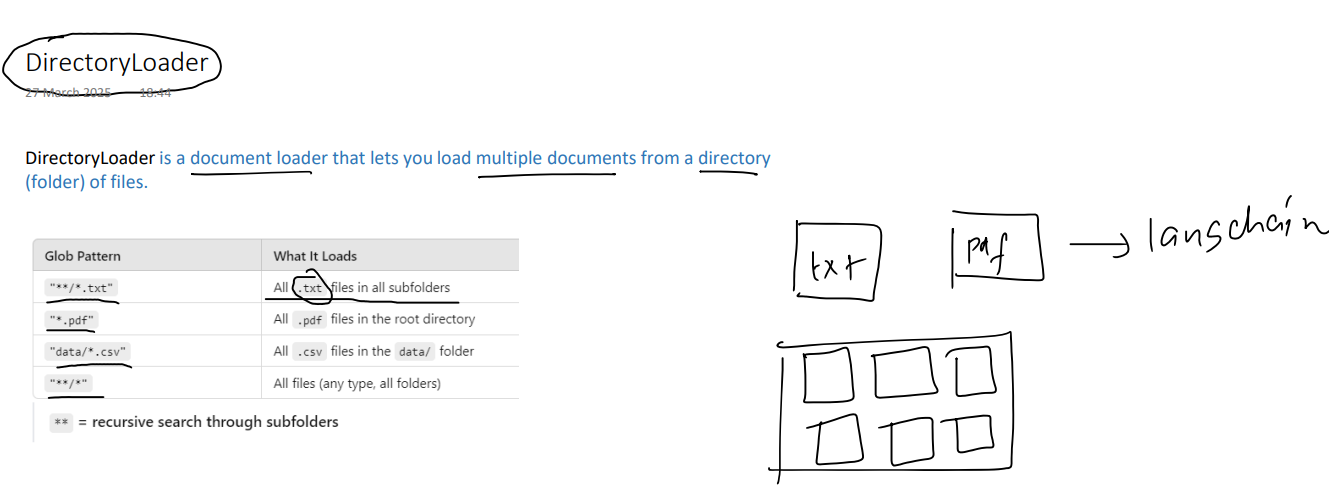

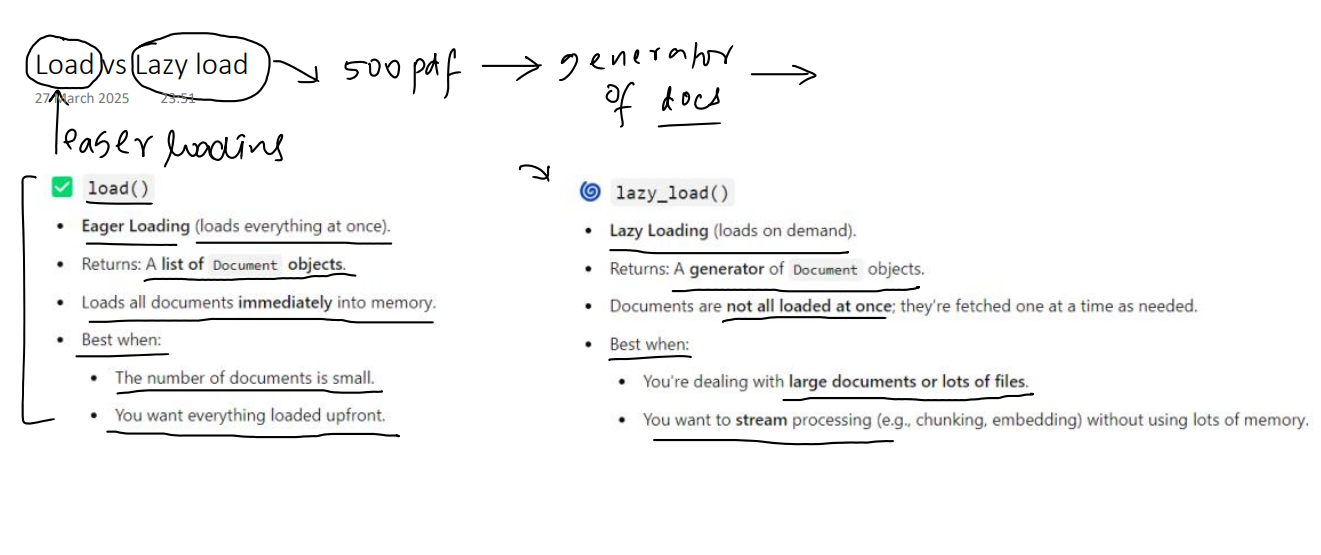

In [1]:
from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader

loader = DirectoryLoader(
    path='books',
    glob='*.pdf',
    loader_cls=PyPDFLoader
)

docs = loader.lazy_load()

for document in docs:
    print(document.metadata)

C:\Users\Admin\AppData\Local\Temp\ipykernel_11108\288076168.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader


{'producer': 'dompdf 3.1.0 + CPDF', 'creator': 'PyPDF', 'creationdate': '2026-10-09T15:47:30+05:30', 'moddate': '2026-10-09T15:47:30+05:30', 'title': 'Candidate — SCAV Developer Profile', 'source': 'books\\candidate-scav-report.pdf', 'total_pages': 8, 'page': 0, 'page_label': '1'}
{'producer': 'dompdf 3.1.0 + CPDF', 'creator': 'PyPDF', 'creationdate': '2026-10-09T15:47:30+05:30', 'moddate': '2026-10-09T15:47:30+05:30', 'title': 'Candidate — SCAV Developer Profile', 'source': 'books\\candidate-scav-report.pdf', 'total_pages': 8, 'page': 1, 'page_label': '2'}
{'producer': 'dompdf 3.1.0 + CPDF', 'creator': 'PyPDF', 'creationdate': '2026-10-09T15:47:30+05:30', 'moddate': '2026-10-09T15:47:30+05:30', 'title': 'Candidate — SCAV Developer Profile', 'source': 'books\\candidate-scav-report.pdf', 'total_pages': 8, 'page': 2, 'page_label': '3'}
{'producer': 'dompdf 3.1.0 + CPDF', 'creator': 'PyPDF', 'creationdate': '2026-10-09T15:47:30+05:30', 'moddate': '2026-10-09T15:47:30+05:30', 'title': 'Can

#### webbase loader
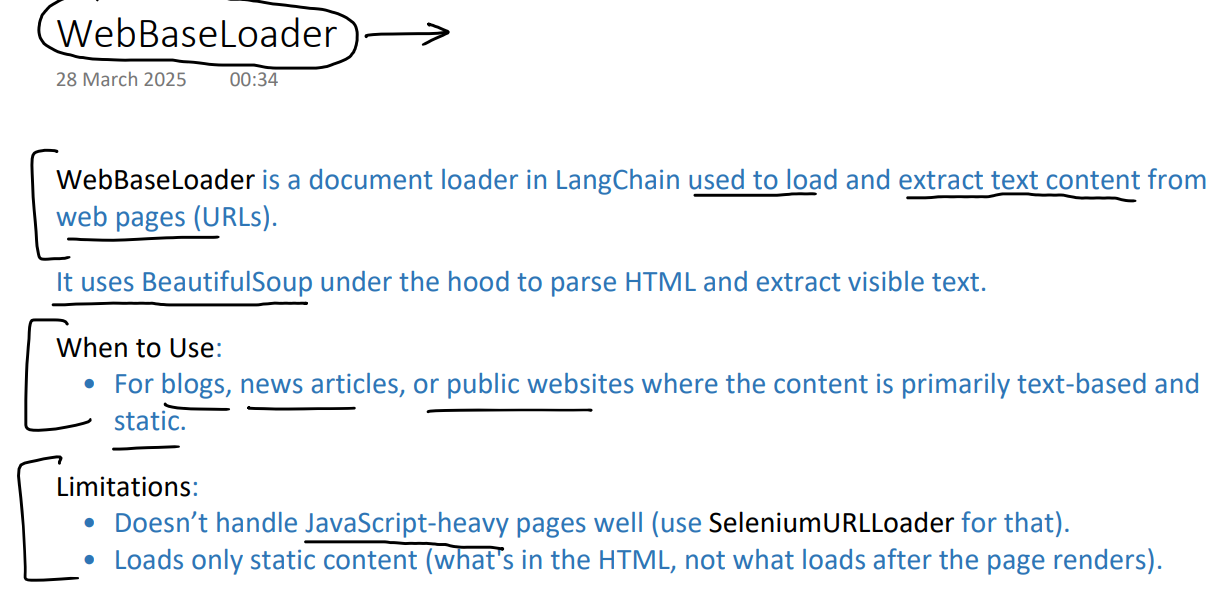

In [4]:
from langchain_community.document_loaders import WebBaseLoader
from langchain_groq import ChatGroq
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv

load_dotenv()

model = ChatGroq(model="openai/gpt-oss-120b")

prompt = PromptTemplate(
    template='Answer the following question \n {question} from the following text - \n {text}',
    input_variables=['question','text']
)

parser = StrOutputParser()

url = 'https://www.flipkart.com/mobiles/pr?sid=tyy,4io&p[]=facets.availability%255B%255D%3DExclude%2BOut%2Bof%2BStock&p[]=facets.brand%255B%255D%3DMOTOROLA&otracker=categorytree&otracker=nmenu_sub_Electronics_0_Motorola'
loader = WebBaseLoader(url)

docs = loader.load()


chain = prompt | model | parser

print(chain.invoke({'question':'What is the product that we are talking about?', 'text':docs[0].page_content}))

The text is referring to **air conditioners (ACs)** – it’s an “Buy ACs Online in Big Billion Days Sale” listing.


#### CSV LOADER
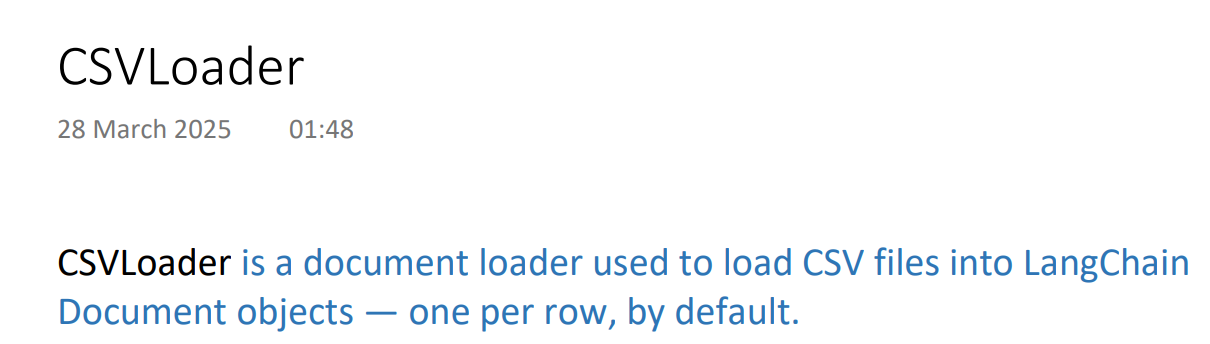

In [6]:
from langchain_community.document_loaders import CSVLoader

loader = CSVLoader(file_path='SN.csv')

docs = loader.load()

print(len(docs))
print(docs[1])

400
page_content='User ID: 15810944
Gender: Male
Age: 35
EstimatedSalary: 20000
Purchased: 0' metadata={'source': 'SN.csv', 'row': 1}
